# Neural-network optimisation

This undergraduate project compares event-selection cuts and neural networks using university-provided simulated data. The notebook presents completed analysis and selected historical results.

The data and provided helper implementations are not redistributed. Their roles are explained where they affect the analysis. Selected code illustrates my project logic; full reproducibility is not claimed. Read the saved outputs without running all cells, which would clear the historical output archive.

See the [project overview](../README.md) and [provenance](../PROVENANCE.md). This is an independent project, not an official ATLAS analysis.


Explicit imports support the retained illustrative project functions. They do not supply the omitted analysis environment.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import random
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense


## Neural-network optimisation

I compared preprocessing and model settings using validation sensitivity. The historical five-input, one-hidden-layer baseline was adapted from the supplied ATLAS NN methodology and is not claimed as original architecture design.

The historical analysis loaded the university-provided training, validation and test CSVs. They are omitted. Validation was used for NN configuration comparisons; the test sample was used for final NN reporting. Absolute sensitivity differs across samples because their total event weights differ.

`scale_prepare_data` fitted a scaler on training features, applied it to validation/test features, and extracted labels and training weights. Inputs were dRBB, mBB, MET, Mtop and pTV. The original provided helper is not redistributed or reimplemented.

The adapted baseline used five ReLU hidden units, a sigmoid output, SGD and binary cross-entropy. Its baseline-derived function scaffolding is replaced by this description.

The baseline was trained for 12 epochs with batch size 64 and supplied training weights. The baseline-derived training cell and epoch log are omitted. No training is performed by this portfolio.

The baseline validation score was computed with `sensitivity_NN`, which constructed adaptive score bins and propagated weighted-yield uncertainty. The provided implementation is omitted. The saved scalar result is retained; the helper-rendered score plot containing inherited "ATLAS Internal" is omitted.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



A sensitivity of 0.91 ± 0.05 was achieved


The historical samples contained 77,176 training events and 16,538 events in each of validation and test. Counts are aggregate metadata, not event records.

Equal validation/test event counts did not imply equal total signal and background weights. The historical aggregate weighted-yield diagnostic is retained below; it is not an event-level data extract.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



train weighted signal = 34.558081089645356 weighted background = 3399.645990117242
val weighted signal = 7.382792272242784 weighted background = 718.8369596436146
test weighted signal = 48.84488978693011 weighted background = 4872.571749667638


## Study design

I compared scaling, optimiser, layer widths and depths, epochs, batch size, hidden activation and loss using validation results. The historical search changed one setting at a time rather than conducting a joint global optimisation.

## Preprocessing comparison

The same baseline configuration was used for the two historical scaling trials.

Standard scaling was fitted to the training sample by the omitted `scale_prepare_data` helper and applied unchanged to the other samples.

The standard-scaled baseline was retrained for 12 epochs with batch size 64. Repeated baseline scaffolding and its training log are omitted.

Saved standard-scaled validation result. The approximately 0.05 uncertainty is the provided evaluator's propagated uncertainty for this individual run, not a repeat-to-repeat standard deviation. The annotated helper plot is omitted.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



A sensitivity of 0.86 ± 0.05 was achieved


### Min-max scaling

Min-max scaling was fitted to training features by the omitted provided helper and applied to validation/test features.

The min-max-scaled baseline used 12 epochs and batch size 64. The repeated baseline training cell and log are omitted.

Saved min-max validation result, with propagated individual-run uncertainty. The annotated helper plot is omitted.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



A sensitivity of 0.45 ± 0.01 was achieved


The saved standard-scaled trial achieved about 0.86 versus 0.45 for min-max scaling. These were individual trials, not means over repeated scaling experiments.

## Repeated model comparisons

For the subsequent scans, I reset Python, NumPy and TensorFlow random seeds before each training and compared mean validation sensitivity across eight runs. Small differences relative to the spread were treated cautiously. The historical hash-environment assignment does not retroactively fix hashing in an already running interpreter, and TensorFlow determinism was not explicitly enabled.

The following project seeding function is retained unchanged as historical code, including its limitations. It is not called here.

In [ ]:
# fix random seeds for each repeat for reproducibility 
def set_all_seeds(seed):
    """
    Set random seeds for reproducible model training.

    Parameters
    ----------
    seed : int
        Seed applied to Python, NumPy, TensorFlow, and the Python hash
        environment variable.

    Returns
    -------
    None
        The function updates global random-state settings in place.
    """
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

The configurable model builder below is retained from my project extension of the adapted dense-network baseline. The Sequential/Dense binary-classifier pattern follows provided baseline methodology; configurable widths, depths and parameters supported my scan. It is illustrative model-building code, not a training pipeline.

In [ ]:
# build model with diff params
def build_classifier(input_dim, hidden_layers=[5], activation='relu',
    output_activation='sigmoid', optimizer='SGD', loss='binary_crossentropy'):
    """
    Build and compile a configurable dense neural-network classifier.

    Parameters
    ----------
    input_dim : int
        Number of input features.
    hidden_layers : list[int], optional
        Width of each hidden layer, in order from input to output.
    activation : str, optional
        Activation function used for all hidden layers.
    output_activation : str, optional
        Activation function used in the output layer. For binary
        classification this is typically 'sigmoid'.
    optimizer : str or keras optimizer, optional
        Optimizer used during training.
    loss : str, optional
        Loss function used when compiling the model.

    Returns
    -------
    tensorflow.keras.Model
        Compiled Keras Sequential model with the requested architecture.
    """
    model = Sequential()

    # input layer
    model.add(Input(shape=(input_dim,)))

    # hidden layers
    for units in hidden_layers:
        model.add(Dense(units, activation=activation))

    # output layer
    model.add(Dense(1, activation=output_activation))

    model.compile(loss=loss,optimizer=optimizer,metrics=['accuracy'])
    return model

Standard scaling was restored through the omitted provided helper before the repeated parameter studies.

## Optimiser comparison

The repeated optimisation studies used seeds [101, 202, 303, 404, 505, 606, 707, 808].

I compared SGD and Adam with the five-unit baseline, ReLU, binary cross-entropy, 12 epochs and batch size 64. Each run used supplied training weights and validation data. `sensitivity_NN` scored each run; `mean_std_sensitivity(drop=0)` returned the mean and population standard deviation without trimming. Both omitted university-provided resources are described here rather than copied. Only the saved configuration-level summary is retained.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



  optimizer  mean_sensitivity  std_sensitivity  min_sensitivity  \
1      adam          0.991665         0.053792         0.907994   
0       SGD          0.881802         0.053616         0.789834   

   max_sensitivity  
1         1.086991  
0         0.950639  


Adam had higher mean validation sensitivity and was selected.

## Hidden-layer width

I scanned one-layer widths [4, 8, 16, 24, 32, 40, 48] with Adam, ReLU, binary cross-entropy, 12 epochs and batch size 64 across the eight seeds. Scores and population-standard-deviation summaries used the omitted provided evaluators. The saved aggregate table is retained.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



  nodes  mean_sensitivity  std_sensitivity  min_sensitivity  max_sensitivity
0   [4]          0.922879         0.053392         0.846101         1.026017
1   [8]          0.979668         0.043718         0.896531         1.033079
2  [16]          1.025694         0.030600         0.979153         1.068138
3  [24]          0.996041         0.025414         0.952972         1.041050
4  [32]          0.999028         0.033070         0.963615         1.080265
5  [40]          0.996011         0.020300         0.976411         1.035547
6  [48]          0.999891         0.022896         0.976782         1.042935


Historical width-scan figure and my plotting code. The code references the historical aggregate `summary_df_nodes` table; it is shown as a reading excerpt, not executed or populated with replacement data.

Illustrative historical plotting excerpt (not executed; aggregate tables are not reconstructed):

```python
# plot mean sensitivity against number of nodes 
plot_df = summary_df_nodes.copy()

# convert to integer
plot_df['n_nodes'] = plot_df['nodes'].apply(lambda x: x[0] if isinstance(x, list) else x)

plot_df = plot_df.sort_values('n_nodes')

# axes and erros 
x = plot_df['n_nodes']
y = plot_df['mean_sensitivity']
yerr = plot_df['std_sensitivity']

# plot 
plt.figure(figsize=(8,5))
plt.errorbar(x, y, yerr=yerr, fmt='o-', capsize=4)
plt.xlabel('Number of nodes in hidden layer')
plt.ylabel('Mean sensitivity')
plt.title('Sensitivity variation with number of nodes')
plt.grid(True, alpha=0.3)
plt.show()
```

**Saved historical output; not regenerated for this portfolio.** 

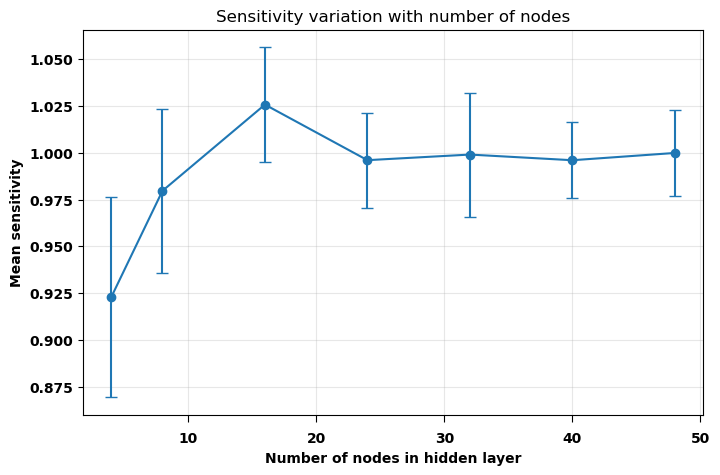

In [ ]:
# Historical output archive; display only



Mean sensitivity peaked near 16 units; wider models did not show a clear gain.

## Hidden-layer architecture

I compared [16], [16, 8], [32, 16, 8] and [32, 16, 8, 4] with the same optimiser, activations, loss, epochs and batch size. The retained table was summarised using the omitted provided evaluation functions.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



    hidden_layers  n_hidden_layers  mean_sensitivity  std_sensitivity  \
0            [16]                1          1.025694         0.030600   
1         [16, 8]                2          1.029377         0.035702   
2     [32, 16, 8]                3          1.024013         0.025546   
3  [32, 16, 8, 4]                4          0.988120         0.043403   

   min_sensitivity  max_sensitivity  
0         0.979153         1.068138  
1         0.996186         1.114077  
2         0.984510         1.061158  
3         0.903359         1.051770  


Historical architecture-scan figure and plotting excerpt, using the original aggregate `summary_df_layers` table.

Illustrative historical plotting excerpt (not executed; aggregate tables are not reconstructed):

```python
# plot results for different sensitivities
plot_df = summary_df_layers.copy()

# string for plotting 
x_labels = plot_df['hidden_layers'].astype(str)
y = plot_df['mean_sensitivity']
yerr = plot_df['std_sensitivity']

# plot results 
plt.figure(figsize=(8,5))
plt.errorbar(range(len(x_labels)), y, yerr=yerr, fmt='o-', capsize=4)
plt.xticks(range(len(x_labels)), x_labels, rotation=20)
plt.xlabel('Hidden-layer architecture')
plt.ylabel('Mean sensitivity')
plt.title('Sensitivity variation with hidden-layer architecture')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
```

**Saved historical output; not regenerated for this portfolio.** 

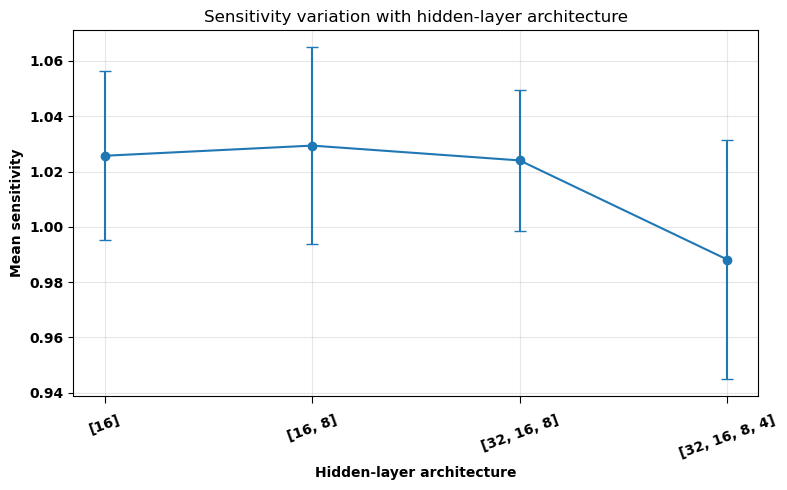

In [ ]:
# Historical output archive; display only



Compact one-to-three-layer models performed similarly relative to run-to-run spread. I selected [16, 8], which had the highest mean in this scan.

## Epochs

I scanned [5, 8, 12, 20, 30, 40, 60, 80] epochs for the [16, 8] model with batch size 64. The saved aggregate validation summary used the omitted sensitivity and mean/spread helpers.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



   epochs  mean_sensitivity  std_sensitivity  min_sensitivity  max_sensitivity
0       5          0.995317         0.032549         0.960523         1.046261
1       8          1.011524         0.030122         0.977788         1.061410
2      12          1.029377         0.035702         0.996186         1.114077
3      20          1.038326         0.030827         0.991649         1.086544
4      30          1.036437         0.024204         0.988896         1.062963
5      40          1.022716         0.014982         0.990513         1.047873
6      60          1.022438         0.017100         0.996356         1.042006
7      80          1.029357         0.018098         0.992262         1.051105


Historical epoch-scan figure and plotting excerpt, using `summary_df_epochs`.

Illustrative historical plotting excerpt (not executed; aggregate tables are not reconstructed):

```python
# plot mean sensitivity against number of epochs
plot_df = summary_df_epochs.copy()

# convert to integer
plot_df['n_epochs'] = plot_df['epochs'].apply(lambda x: x[0] if isinstance(x, list) else x)

plot_df = plot_df.sort_values('n_epochs')

# axes and erros 
x = plot_df['n_epochs']
y = plot_df['mean_sensitivity']
yerr = plot_df['std_sensitivity']

# plot 
plt.figure(figsize=(8,5))
plt.errorbar(x, y, yerr=yerr, fmt='o-', capsize=4)
plt.xlabel('Number of epochs')
plt.ylabel('Mean sensitivity')
plt.title('Sensitivity variation with number of epochs')
plt.grid(True, alpha=0.3)
plt.show()
```

**Saved historical output; not regenerated for this portfolio.** 

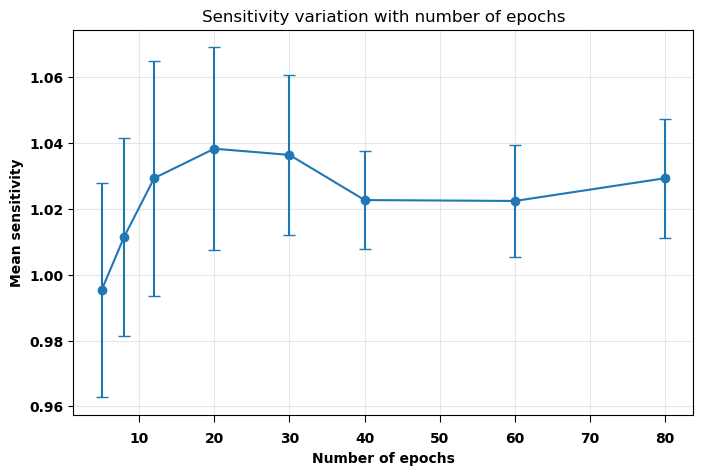

In [ ]:
# Historical output archive; display only



The highest mean occurred at 20 epochs; longer training did not clearly improve sensitivity.

## Batch size

I compared batch sizes [16, 32, 64, 128, 256] at 20 epochs for the [16, 8] model. The saved validation summary used the omitted provided evaluators.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



   batch_size  mean_sensitivity  std_sensitivity  min_sensitivity  \
0          16          1.020016         0.033780         0.967427   
1          32          1.017927         0.022158         0.977130   
2          64          1.038326         0.030827         0.991649   
3         128          1.029785         0.034894         0.984136   
4         256          1.019792         0.031082         0.967365   

   max_sensitivity  
0         1.065784  
1         1.043773  
2         1.086544  
3         1.101770  
4         1.061248  


Historical batch-size figure and plotting excerpt, using `summary_df_batch`.

Illustrative historical plotting excerpt (not executed; aggregate tables are not reconstructed):

```python
# plot mean sensitivity against number of epochs
plot_df = summary_df_batch.copy()

# convert to integer
plot_df['n_batch'] = plot_df['batch_size'].apply(lambda x: x[0] if isinstance(x, list) else x)

plot_df = plot_df.sort_values('n_batch')

# axes and erros 
x = plot_df['n_batch']
y = plot_df['mean_sensitivity']
yerr = plot_df['std_sensitivity']

# plot 
plt.figure(figsize=(8,5))
plt.errorbar(x, y, yerr=yerr, fmt='o-', capsize=4)
plt.xlabel('Batch size')
plt.ylabel('Mean sensitivity')
plt.title('Sensitivity variation with batch size')
plt.grid(True, alpha=0.3)
plt.show()
```

**Saved historical output; not regenerated for this portfolio.** 

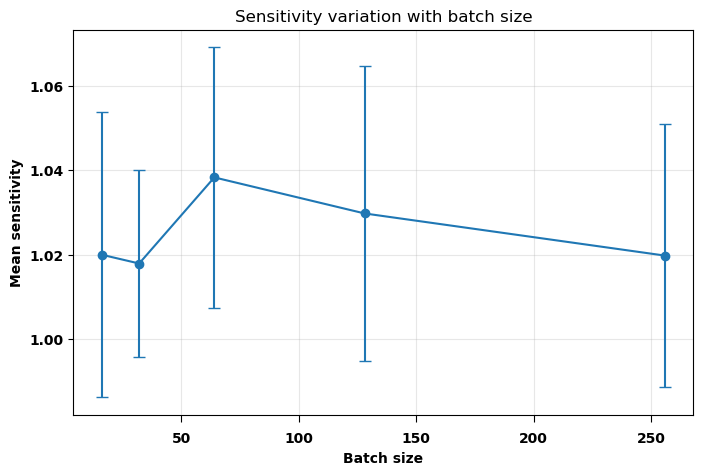

In [ ]:
# Historical output archive; display only



Batch size 64 gave the highest mean in this scan.

## Hidden activation

I compared ReLU, tanh and ELU for [16, 8], Adam, binary cross-entropy, 20 epochs and batch size 64. The saved validation summary used the omitted provided evaluators.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



  activation_function  mean_sensitivity  std_sensitivity  min_sensitivity  \
0                relu          1.038326         0.030827         0.991649   
2                 elu          1.013127         0.022840         0.986968   
1                tanh          1.008137         0.019040         0.984944   

   max_sensitivity  
0         1.086544  
2         1.064496  
1         1.045723  


Historical activation-scan figure and plotting excerpt, using `summary_df_act`.

Illustrative historical plotting excerpt (not executed; aggregate tables are not reconstructed):

```python
# plot results 
plot_df = summary_df_act.copy()

x_labels = plot_df['activation_function'].astype(str)
y = plot_df['mean_sensitivity']
yerr = plot_df['std_sensitivity']

plt.figure(figsize=(8,5))
plt.errorbar(range(len(x_labels)), y, yerr=yerr, fmt='o-', capsize=4)
plt.xticks(range(len(x_labels)), x_labels, rotation=20)
plt.xlabel('Activation function')
plt.ylabel('Mean sensitivity')
plt.title('Sensitivity variation with activation function')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
```

**Saved historical output; not regenerated for this portfolio.** 

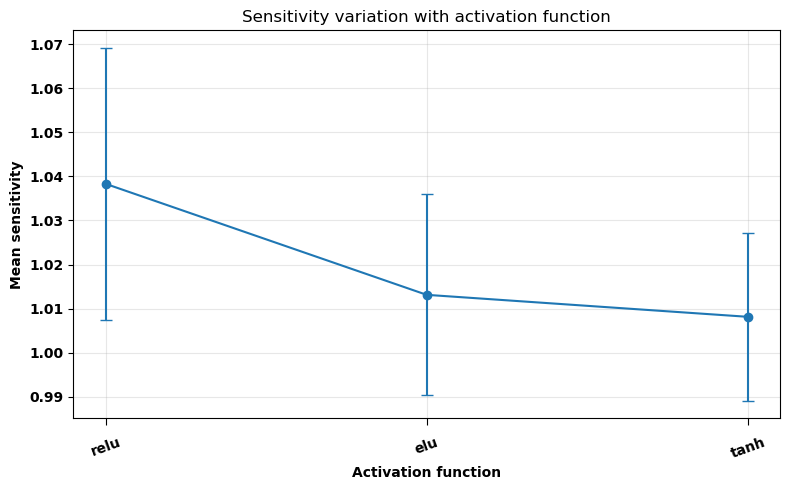

In [ ]:
# Historical output archive; display only



ReLU had the highest mean, but differences were modest relative to the spread.

## Loss

I compared binary cross-entropy and mean squared error with the selected architecture and training settings. The saved validation summary used the omitted provided evaluators.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only


         loss_function  mean_sensitivity  std_sensitivity  min_sensitivity  \
0  binary_crossentropy          1.038326         0.030827         0.991649   
1                  mse          1.012469         0.030643         0.961178   

   max_sensitivity  
0         1.086544  
1         1.061718  


Binary cross-entropy was retained as a conventional sigmoid-classifier loss.

## Selected configuration

The selected configuration was standard scaling, hidden layers [16, 8], ReLU, sigmoid output, Adam, binary cross-entropy, 20 epochs and batch size 64. The final training call and log are omitted; no model was retrained.

Saved final validation result from the omitted `sensitivity_NN` provided evaluator. Its uncertainty is propagated for an individual run. The annotated helper-rendered figure is omitted.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only


A sensitivity of 1.02 ± 0.08 was achieved


The saved validation result was about 1.02 versus 0.91 for the initial baseline, approximately 12% using those rounded values. The original prose's approximate 20% validation-improvement claim is not supported by this pair of saved values.

Saved final test result for this optimisation-notebook run, with individual-run propagated uncertainty. This is a separate historical training from notebook 03, whose repeated-test mean was 2.271. The annotated helper figure is omitted.

**Saved historical output; not regenerated for this portfolio.** 

In [ ]:
# Historical output archive; display only



A sensitivity of 2.25 ± 0.02 was achieved


Absolute validation and test sensitivities are not directly comparable across differently weighted samples. Notebook 03 presents the same-sample cut-versus-NN results and the limitation caused by cut tuning on the combined data.